## ДЗ1


### Подготовка


In [1]:
# %pip install numpy pandas openpyxl matplotlib statsmodels

from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning

pd.set_option('display.max_columns', 10)


In [2]:
def finish_plot(axes, ylabel='Количество, шт.', legend=True):
    for ax in axes:
        ax.set(xlabel='Дата', ylabel=ylabel)
        ax.grid(alpha=0.3)
        if legend:
            ax.legend()
    plt.tight_layout()
    plt.show()


## Задача


### Шаг 1. Изучите данные и сформируйте временной ряд


[Online Retail — UCI](https://archive.ics.uci.edu/dataset/352/online+retail).
При ошибке загрузки используем `data/raw/online+retail.zip`.


In [3]:
URL = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'

def read_retail(data):
    with ZipFile(BytesIO(data)) as archive:
        return pd.read_excel(archive.open('Online Retail.xlsx'), dtype={
            'InvoiceNo': 'string', 'StockCode': 'string', 'CustomerID': 'Int64'
        }, parse_dates=['InvoiceDate'])


def load_retail(url, local_file='data/raw/online+retail.zip'):
    try:
        with urlopen(url, timeout=30) as response:
            return read_retail(response.read()), 'UCI'
    except Exception as error:
        print(f'Используем локальный архив. Ошибка UCI: {error}')
        return read_retail(Path(local_file).read_bytes()), local_file


df, source = load_retail(URL)
print(f'Источник: {source}; размер: {df.shape}')
print('Период:', df.InvoiceDate.min(), '—', df.InvoiceDate.max())
df.head()


Источник: UCI; размер: (541909, 8)
Период: 2010-12-01 08:26:00 — 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


Поля

| Поле | Значение |
| --- | --- |
| InvoiceNo | Счёт; C — отмена |
| StockCode | Код товара |
| Description | Название |
| Quantity | Количество единиц |
| InvoiceDate | Дата и время |
| UnitPrice | Цена в GBP |
| CustomerID | Код покупателя |
| Country | Страна |


In [4]:
display(pd.DataFrame({
    'Тип': df.dtypes.astype(str),
    'Пропуски': df.isna().sum(),
    'Пропуски, %': df.isna().mean().mul(100).round(2),
    'Уникальные значения': df.nunique(),
}))

,Тип,Пропуски,"Пропуски, %",Уникальные значения
InvoiceNo,string,0,0.00,25900
StockCode,string,0,0.00,4070
Description,object,1454,0.27,4223
Quantity,int64,0,0.00,722
InvoiceDate,datetime64[us],0,0.00,23260
UnitPrice,float64,0,0.00,1630
CustomerID,Int64,135080,24.93,4372
Country,str,0,0.00,38


Выбран **47566 — PARTY BUNTING**, праздничная гирлянда из флажков.
У товара заметен весенне-летний подъём спроса; на занятии разбирался 85123A.


In [5]:
STOCK_CODE = '47566'
product = df.loc[df.StockCode.eq(STOCK_CODE)].copy()
product.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
5535,536864,47566,PARTY BUNTING,1,2010-12-03 11:27:00,9.32,<NA>,United Kingdom
5656,536865,47566,PARTY BUNTING,3,2010-12-03 11:28:00,9.32,<NA>,United Kingdom
6022,536876,47566,PARTY BUNTING,2,2010-12-03 11:36:00,8.47,<NA>,United Kingdom
6572,536956,47566,PARTY BUNTING,5,2010-12-03 12:43:00,4.65,14210,United Kingdom
7904,537065,47566,PARTY BUNTING,5,2010-12-05 11:57:00,4.65,12567,France


Показатель — количество проданных единиц `Quantity`, все страны.
Берём положительные количества и счета без префикса C: это продажи без вычета возвратов.
Неделя — понедельник–воскресенье, месяц — календарный.


In [6]:
def aggregate_sales(product, start, end):
    sales = product.loc[(product.Quantity > 0)
                        & ~product.InvoiceNo.str.startswith('C', na=False)]
    quantities = sales.set_index('InvoiceDate').Quantity.sort_index()
    calendar = pd.date_range(start.normalize(), end.normalize(), name='InvoiceDate')
    daily = quantities.resample('D').sum(min_count=1).reindex(calendar)
    weekly = quantities.resample('W-SUN').sum(min_count=1)
    monthly = quantities.resample('MS').sum(min_count=1)
    return daily, weekly, monthly


daily, weekly, monthly = aggregate_sales(product, df.InvoiceDate.min(), df.InvoiceDate.max())
for name, series in [('Дни', daily), ('Недели', weekly), ('Месяцы', monthly)]:
    print(f'{name}: {len(series)} периодов')
    display(series.to_frame().head())


Дни: 374 периодов


,Quantity
InvoiceDate,
2010-12-01,NaN
2010-12-02,NaN
2010-12-03,11.0
2010-12-04,NaN
2010-12-05,8.0


Недели: 54 периодов


,Quantity
InvoiceDate,
2010-12-05,19.0
2010-12-12,165.0
2010-12-19,29.0
2010-12-26,24.0
2011-01-02,NaN


Месяцы: 13 периодов


,Quantity
InvoiceDate,
2010-12-01,237
2011-01-01,486
2011-02-01,925
2011-03-01,1666
2011-04-01,1937


`NaN` означает отсутствие подходящих транзакций за период. Граничные периоды могут быть
неполными: датасет охватывает 01.12.2010–09.12.2011.


### Шаг 2. Оцените качество данных


В исходных `InvoiceDate` и `Quantity` пропусков нет. Принимаем датасет за полный
журнал транзакций: день без покупок означает 0 продаж, в том числе при отсутствии
транзакций всего магазина.


In [7]:
def fill_no_sales(series):
    return series.fillna(0), series.index[series.isna()]


display(pd.Series({
    'Дни': daily.isna().sum(), 'Недели': weekly.isna().sum(),
    'Месяцы': monthly.isna().sum(),
}, name='Периоды без транзакций товара'))
daily_clean, gaps = fill_no_sales(daily)
weekly_clean, _ = fill_no_sales(weekly)
display(gaps.to_frame(index=False, name='Дни без покупок'))
print(f'Дней без покупок: {len(gaps)}; пропусков после заполнения: {daily_clean.isna().sum()}')


Дни       80
Недели     1
Месяцы     0
Name: Периоды без транзакций товара, dtype: int64

,Дни без покупок
0,2010-12-01
1,2010-12-02
2,2010-12-04
3,2010-12-11
4,2010-12-15
...,...
75,2011-11-05
76,2011-11-12
77,2011-11-19
78,2011-11-26


Дней без покупок: 80; пропусков после заполнения: 0


Потенциальные выбросы — значения за границами `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`.
Это диагностические флаги, а не доказанные ошибки: крупные заказы допустимы
для оптовых продаж. Такие значения сохраняем.


In [8]:
def iqr_outliers(series, factor=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    lower, upper = q1 - factor * (q3 - q1), q3 + factor * (q3 - q1)
    outliers = series[(series < lower) | (series > upper)]
    return outliers, (lower, upper)


outliers, (lower, upper) = iqr_outliers(daily_clean)
print(f'Границы IQR: [{lower:.1f}, {upper:.1f}]; потенциальных выбросов: {len(outliers)}')
display(outliers.to_frame('Продажи, шт.'))


Границы IQR: [-88.4, 158.6]; потенциальных выбросов: 27


,"Продажи, шт."
InvoiceDate,
2011-03-17,161.0
2011-03-29,172.0
2011-04-08,171.0
2011-04-20,247.0
2011-04-21,207.0
2011-05-03,279.0
2011-05-04,217.0
2011-05-08,201.0
2011-05-10,338.0


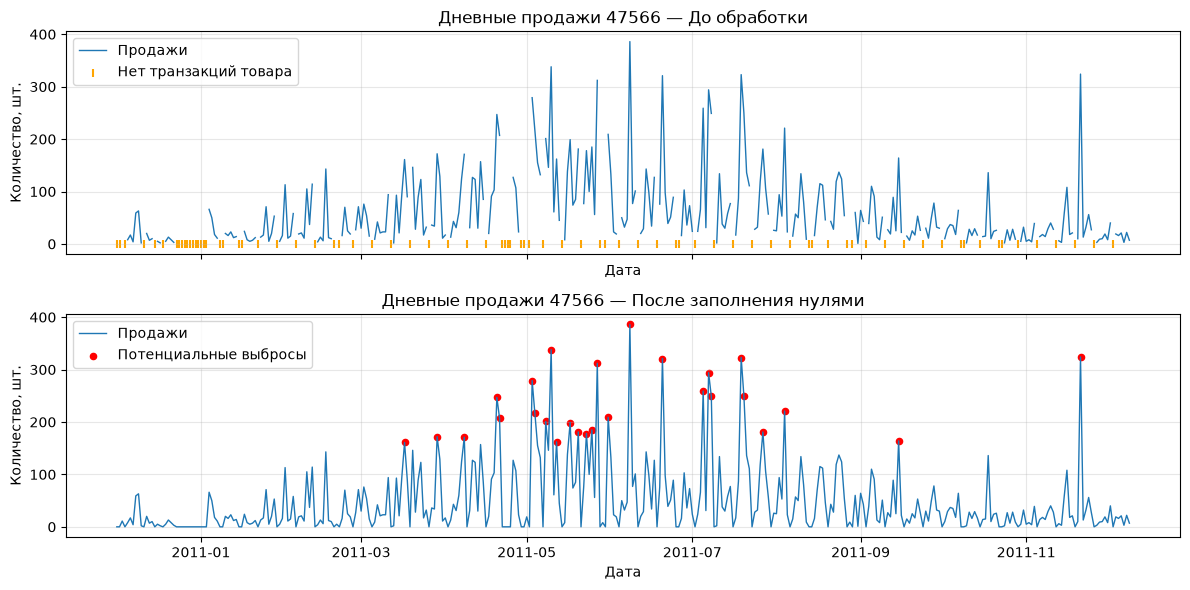

In [9]:
def plot_quality(before, after, outliers, stock_code):
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    for ax, series, title in zip(axes, [before, after], ['До обработки', 'После заполнения нулями']):
        ax.plot(series.index, series, linewidth=1, label='Продажи')
        ax.set_title(f'Дневные продажи {stock_code} — {title}')
    gaps = before.index[before.isna()]
    axes[0].scatter(gaps, [0] * len(gaps), marker='|', color='orange', label='Нет транзакций товара')
    axes[1].scatter(outliers.index, outliers, color='red', s=20, label='Потенциальные выбросы')
    finish_plot(axes)


plot_quality(daily, daily_clean, outliers, STOCK_CODE)


Все 80 дней без покупок заполнены нулями; пропусков в ряду нет. Найдено 27 пиков
выше 158.6 шт. Ошибками их не считаем: проверенные пики включают крупные оптовые
заказы. Например, 21.11.2011 из 324 штук 300 пришлись на два заказа по 150.
Общий порог IQR также может отмечать периоды повышенного спроса. Значения сохраняем.
Для дальнейшего анализа используем `daily_clean` и `weekly_clean`.


### Шаг 3. Проведите визуальный и описательный анализ


Дневные статистики считаем по всем 374 календарным дням. Для недель исключаем
оба граничных интервала, для месяцев — неполный декабрь 2011.
`CV = std / mean` показывает относительный разброс.


In [10]:
def describe_series(series_by_freq):
    stats = pd.DataFrame({name: series.describe() for name, series in series_by_freq.items()}).T
    stats['CV'] = stats['std'] / stats['mean']
    return stats.round(2)


stats = describe_series({
    'Дни': daily_clean, 'Недели': weekly_clean.iloc[1:-1], 'Месяцы': monthly.iloc[:-1],
})
stats


,count,mean,std,min,25%,50%,75%,max,CV
Дни,374.0,48.93,67.34,0.0,4.25,21.5,66.0,386.0,1.38
Недели,52.0,350.21,251.85,0.0,163.25,284.0,480.0,984.0,0.72
Месяцы,12.0,1513.58,991.88,237.0,842.00,1401.5,2008.0,3565.0,0.66


Изменение уровня и разброса оцениваем по скользящим среднему и стандартному
отклонению за 28 календарных дней. На графиках недель и месяцев оставлены
также неполные граничные периоды.


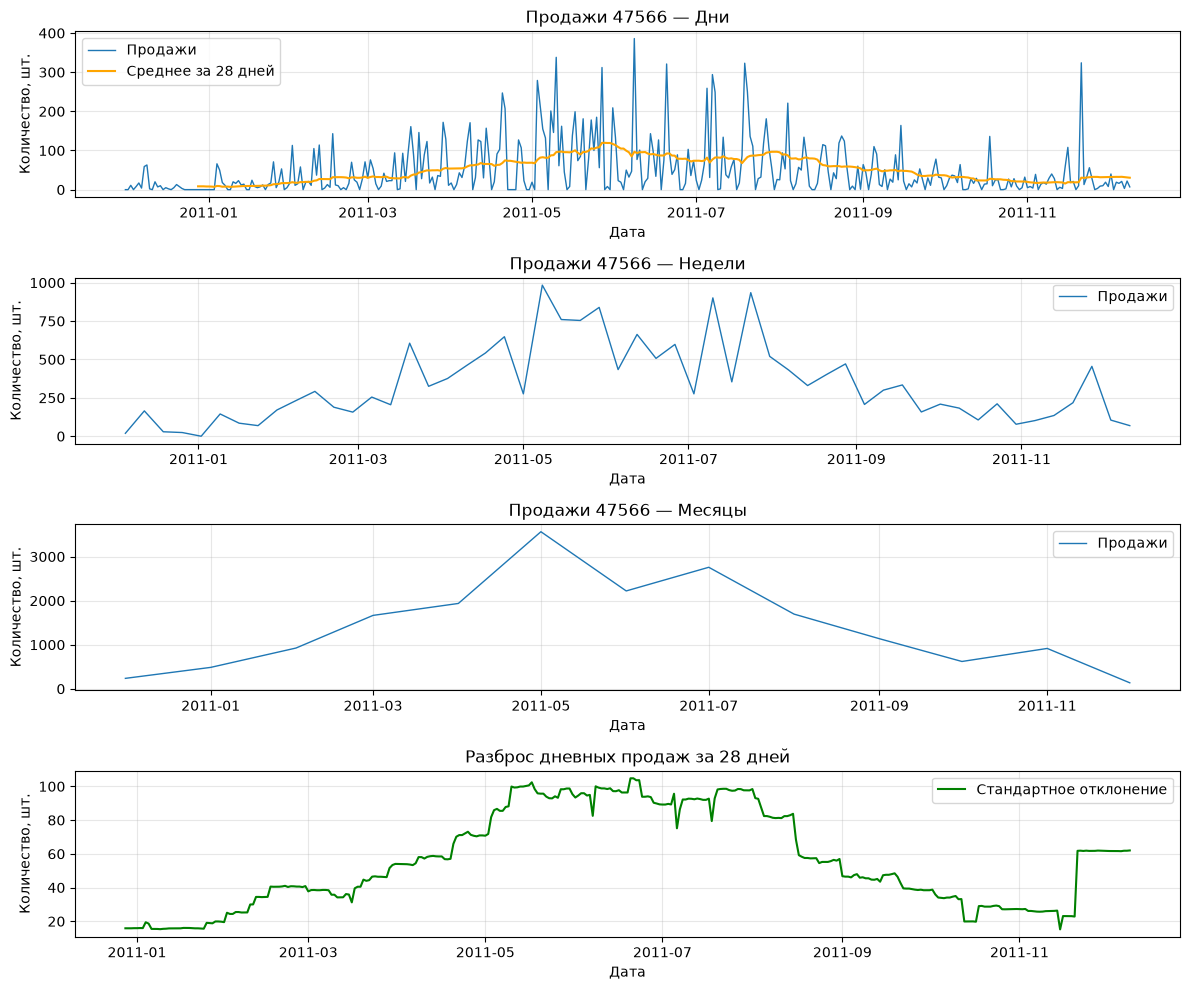

In [11]:
def rolling_summary(series, window=28):
    rolling = series.rolling(window)
    return pd.DataFrame({'mean': rolling.mean(), 'std': rolling.std()})


def plot_dynamics(daily, weekly, monthly, stock_code, window=28):
    rolling = rolling_summary(daily, window)
    fig, axes = plt.subplots(4, 1, figsize=(12, 10))
    for ax, series, title in zip(axes, [daily, weekly, monthly], ['Дни', 'Недели', 'Месяцы']):
        ax.plot(series.index, series, linewidth=1, label='Продажи')
        ax.set_title(f'Продажи {stock_code} — {title}')
    axes[0].plot(rolling.index, rolling['mean'], color='orange', label=f'Среднее за {window} дней')
    axes[3].plot(rolling.index, rolling['std'], color='green', label='Стандартное отклонение')
    axes[3].set_title(f'Разброс дневных продаж за {window} дней')
    finish_plot(axes)


plot_dynamics(daily_clean, weekly_clean, monthly, STOCK_CODE)


Среднее — 48.9 шт. в календарный день, медиана — 21.5. Агрегация сглаживает
дневные колебания: CV снижается с 1.38 до 0.72 для недель и 0.66 для месяцев.
Продажи растут с 486 шт. в январе до 3565 в мае, затем снижаются до 620 в октябре.
Скользящее среднее меняется от 7 до 120 шт., стандартное отклонение — от 15 до 105 шт.
Видна весенне-летняя волна спроса; годовая сезонность пока остаётся гипотезой,
поскольку доступен примерно один цикл.


### Шаг 4. Выполните декомпозицию временного ряда


Аддитивная STL: `продажи = тренд + сезонность + остаток`. Период — 7 дней
(календарная неделя), окно тренда — 29 дней. Метод допускает нулевые продажи;
`robust=True` уменьшает влияние крупных заказов на оценку компонент.


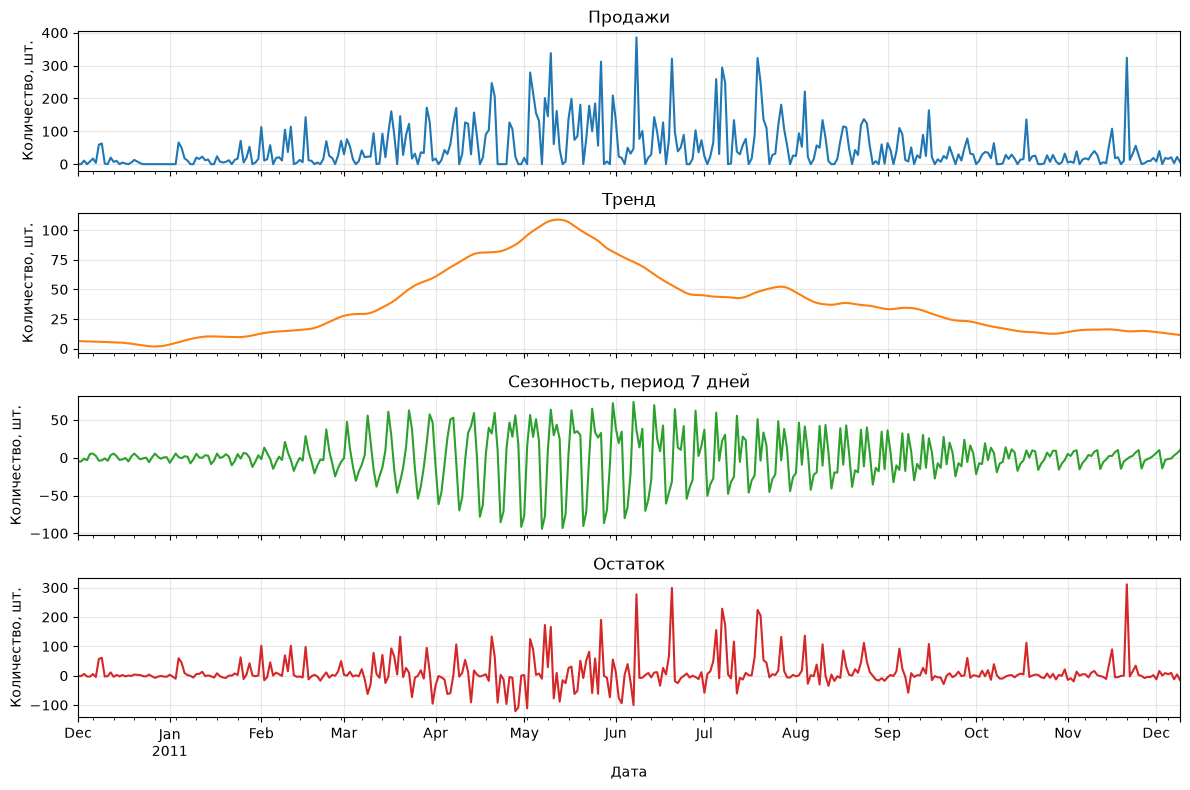

In [12]:
def decompose_sales(series, period=7, seasonal=13, trend=29):
    result = STL(series, period=period, seasonal=seasonal, trend=trend, robust=True).fit()
    components = pd.DataFrame({
        'Продажи': series, 'Тренд': result.trend,
        f'Сезонность, период {period} дней': result.seasonal, 'Остаток': result.resid,
    })
    axes = components.plot(subplots=True, figsize=(12, 8), legend=False)
    for ax, title in zip(axes, components):
        ax.set_title(title)
    finish_plot(axes, legend=False)
    return result


decomposition = decompose_sales(daily_clean)


Проверяем недельный рисунок по ACF ряда без тренда на лагах, кратных 7.
Сила сезонности `F_s = max(0, 1 − Var(остаток) / Var(сезонность + остаток))`:
чем ближе к 1, тем выраженнее компонента относительно остаточных колебаний.


In [13]:
def seasonality_diagnostics(series, decomposition, period=7, n_periods=4):
    strength = max(0, 1 - decomposition.resid.var()
                   / (decomposition.seasonal + decomposition.resid).var())
    values, ci = acf(series - decomposition.trend, nlags=period * n_periods,
                     alpha=0.05, result_object=False)
    lags = list(range(period, period * (n_periods + 1), period))
    table = pd.DataFrame({
        'ACF': values[lags], 'Нижняя граница 95%': ci[lags, 0],
        'Верхняя граница 95%': ci[lags, 1],
    }, index=pd.Index(lags, name='Лаг, дней'))
    return strength, table.round(3)


seasonal_strength, acf_table = seasonality_diagnostics(daily_clean, decomposition)
print(f'Сила недельной сезонности: {seasonal_strength:.3f}')
display(acf_table)


Сила недельной сезонности: 0.250


,ACF,Нижняя граница 95%,Верхняя граница 95%
"Лаг, дней",,,
7,0.240,0.130,0.350
14,0.245,0.119,0.372
21,0.202,0.063,0.340
28,0.251,0.101,0.401


Тренд растёт к маю и снижается осенью. Недельная компонента в среднем выше
во вторник и четверг, минимум — в субботу. Недельный рисунок поддерживается ACF:
на лагах 7, 14, 21 и 28 дней значения положительны, 95%-интервалы не включают 0.
Сила сезонности — 0.25; в остатке сохраняются значительные нерегулярные пики.
Весенне-летняя волна вошла в тренд: подтвердить её как годовую сезонность
по одному годовому циклу нельзя.


### Шаг 5. Проверьте стационарность


ADF: H0 — наличие единичного корня. KPSS: H0 — стационарность вокруг постоянного
уровня. При `p < 0.05` соответствующую H0 отвергаем. Граничные p-value KPSS
показываем неравенствами, поскольку его таблица ограничена диапазоном 0.01–0.10.

Применяем `log1p`, чтобы уменьшить разброс и сохранить нули, затем разность
`z[t] − z[t−7]` для устранения недельного рисунка и изменений уровня.


In [14]:
def stationarity_test(series):
    a = adfuller(series, regression='c', autolag='AIC', result_object=False)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', InterpolationWarning)
        k = kpss(series, regression='c', nlags='auto', result_object=False)
    p_k = '≤0.01' if k[1] == 0.01 else '≥0.10' if k[1] == 0.1 else f'{k[1]:.3g}'
    return {'n': len(series), 'ADF': round(a[0], 3), 'p ADF': f'{a[1]:.3g}',
            'KPSS': round(k[0], 3), 'p KPSS': p_k}


def compare_stationarity(series, lag=7):
    transformed = np.log1p(series).diff(lag).dropna()
    table = pd.DataFrame({
        'Исходный': stationarity_test(series),
        f'log1p и разность {lag}': stationarity_test(transformed),
    }).T
    return transformed, table


transformed, stationarity_results = compare_stationarity(daily_clean)
display(stationarity_results)


,n,ADF,p ADF,KPSS,p KPSS
Исходный,374,-1.93,0.318,0.911,≤0.01
log1p и разность 7,367,-6.75,2.97e-09,0.066,≥0.10


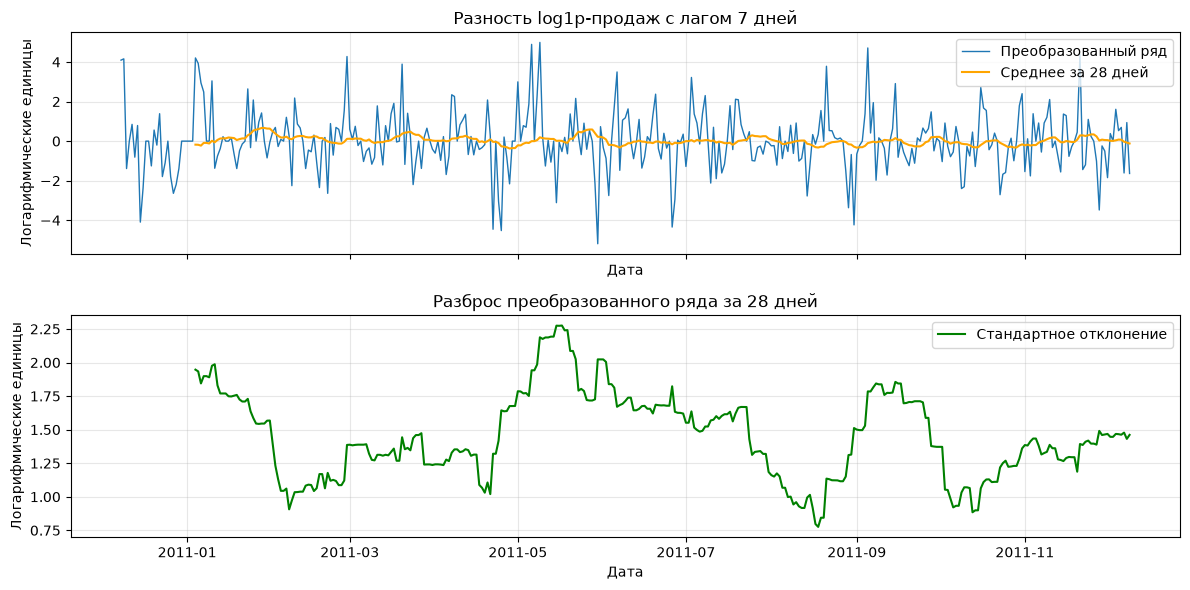

In [15]:
def plot_transformed(series, lag=7, window=28):
    rolling = rolling_summary(series, window)
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    axes[0].plot(series.index, series, linewidth=1, label='Преобразованный ряд')
    axes[0].plot(rolling.index, rolling['mean'], color='orange', label=f'Среднее за {window} дней')
    axes[0].set_title(f'Разность log1p-продаж с лагом {lag} дней')
    axes[1].plot(rolling.index, rolling['std'], color='green', label='Стандартное отклонение')
    axes[1].set_title(f'Разброс преобразованного ряда за {window} дней')
    finish_plot(axes, ylabel='Логарифмические единицы')


plot_transformed(transformed)


Исходный ряд: ADF не отвергает единичный корень (`p = 0.318`), KPSS отвергает
стационарность (`p ≤ 0.01`). После `log1p` и разности с лагом 7 ADF отвергает
единичный корень (`p ≈ 3·10⁻⁹`), KPSS не отвергает стационарность (`p ≥ 0.10`).
Тесты поддерживают стационарность уровня преобразованного ряда. При этом
скользящее стандартное отклонение меняется от 0.78 до 2.28: постоянство
дисперсии не установлено, поэтому полную стационарность не утверждаем.


### Шаг 6. Оформите методы анализа в функции или классы


Расчёты, предобработка и графики оформлены в функции в шагах 1–5; там же показаны
их вызовы для выбранного товара. Входные данные передаются аргументами.
Notebook выполняется по порядку с чистого ядра.


### Шаг 7. Подготовьте выводы


Я разобрал продажи **47566 — PARTY BUNTING**, гирлянды из флажков,
за 01.12.2010–09.12.2011. Продажи в штуках посчитал по дням, неделям и месяцам.

- В датах и количествах пропусков нет. В 80 днях покупок товара не было,
  поэтому я поставил 0, считая журнал транзакций полным.
- По IQR нашлось 27 потенциальных выбросов. Я их оставил: проверенные пики
  складываются из крупных оптовых заказов, поэтому оснований удалять их как ошибки нет.
- Спрос заметно менялся: в январе продали 486 штук, в мае — 3565, в октябре — 620.
  В среднем получалось 48.9 штуки в день, медиана — 21.5. Крупные заказы поднимают
  среднее, а недельная и месячная агрегации сглаживают дневные колебания.
- STL и ACF показывают недельный ритм: продажи обычно выше во вторник и четверг,
  минимум — в субботу. При этом большая часть колебаний остаётся нерегулярной.
  Весенне-летний подъём есть, но подтвердить годовую сезонность по одному году нельзя.
- Исходный ряд не проходит проверку стационарности. После `log1p` и разности
  с лагом 7 результаты ADF и KPSS согласуются со стационарностью уровня.
  Разброс по времени всё ещё меняется, поэтому полностью стационарным ряд не называю.

Для дальнейшего прогноза нужно учитывать недельный ритм, изменение спроса
и крупные заказы. Для более уверенных выводов о годовой сезонности нужна история подлиннее.
